# Stage 4 - Evaluation and Business Checkpoint
## Delivered (1) vs Delayed (0)

The model and threshold were frozen on validation data. The **untouched test
split** is used here once. The candidate is compared with the naive majority
baseline on predictive metrics, on business economics, and against the
configured business gates. Returned orders are not part of this problem.

In [1]:
from pathlib import Path
import sys

# Locate the project root (the folder containing mlops_pipeline/) from any notebook folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mlops_pipeline").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FEATURE_STORE = ROOT / "artifacts" / "feature_store"
REPORTS = ROOT / "artifacts" / "reports"
FIGURES = ROOT / "artifacts" / "notebook_figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\Vivek Kumar Singh\Downloads\E-Commerce-Shipping-Prediction-main\E-Commerce-Shipping-Prediction-main


In [2]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

from mlops_pipeline.business import classification_economics
from mlops_pipeline.config import PipelineConfig
from mlops_pipeline.model_stage import _metrics

config = PipelineConfig()
selection = json.loads((REPORTS / "analytical_model_selection.json").read_text(encoding="utf-8"))
report = json.loads((REPORTS / "evaluation_report.json").read_text(encoding="utf-8"))

X_train = pd.read_csv(FEATURE_STORE / "X_train.csv")
y_train = pd.read_csv(FEATURE_STORE / "y_train.csv")["binary_target"]
X_test = pd.read_csv(FEATURE_STORE / "X_test.csv")
y_test = pd.read_csv(FEATURE_STORE / "y_test.csv")["binary_target"]
model = joblib.load(ROOT / "artifacts" / "model_registry" / "candidate_model.joblib")
threshold = float(selection["validation_selected_threshold"])
print("Candidate:", selection["selected_model"], "| threshold:", threshold, "| test rows:", len(X_test))
print("Test classes (1=Delivered, 0=Delayed):", y_test.value_counts().to_dict())

Candidate: xgboost | threshold: 0.85 | test rows: 9514
Test classes (1=Delivered, 0=Delayed): {1: 8013, 0: 1501}


### 1. Candidate vs naive baseline on the test set

In [3]:
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
candidate_m = _metrics(y_test, pred, proba)
baseline_m = _metrics(y_test, baseline.predict(X_test), baseline.predict_proba(X_test)[:, 1])
keys = ["roc_auc", "accuracy", "balanced_accuracy", "f1_weighted", "minority_recall", "minority_precision", "average_precision_delayed"]
table = pd.DataFrame({"candidate": [candidate_m[k] for k in keys], "naive_baseline": [baseline_m[k] for k in keys]}, index=keys).round(4)
assert abs(candidate_m["roc_auc"] - report["candidate_test_metrics"]["roc_auc"]) < 1e-9
table

,candidate,naive_baseline
roc_auc,0.4890,0.5000
accuracy,0.5055,0.8422
balanced_accuracy,0.4928,0.5000
f1_weighted,0.5717,0.7701
minority_recall,0.4744,0.0000
minority_precision,0.1538,0.0000
average_precision_delayed,0.1524,0.1578


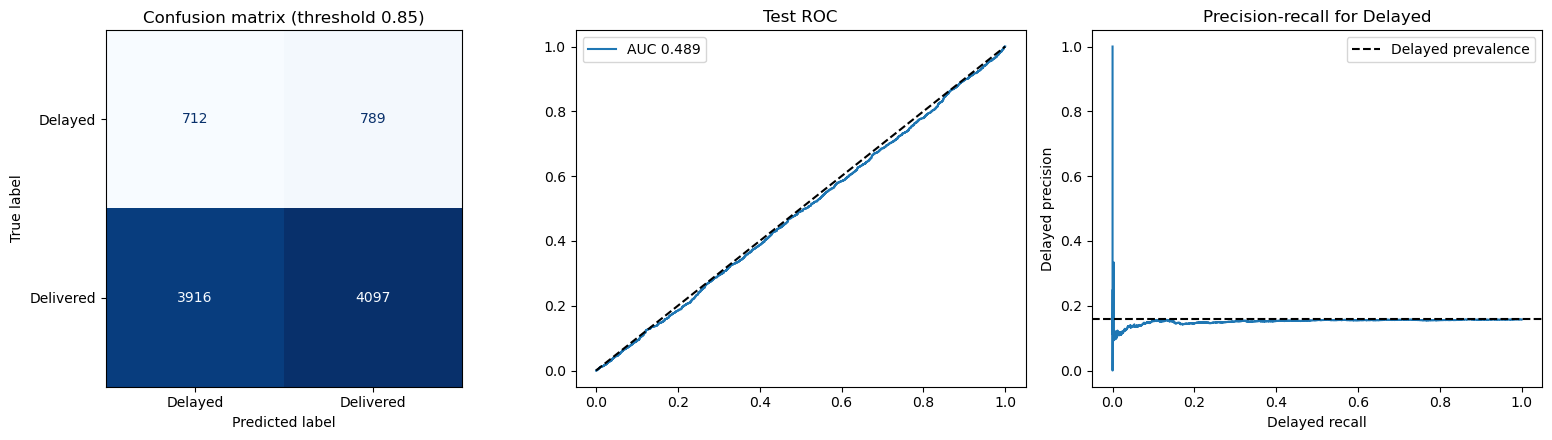

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=["Delayed", "Delivered"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {threshold:.2f})")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"AUC {candidate_m['roc_auc']:.3f}"); axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Test ROC"); axes[1].legend()
prec, rec, _ = precision_recall_curve(1 - y_test, 1 - proba)
axes[2].plot(rec, prec); axes[2].axhline((y_test == 0).mean(), color="k", linestyle="--", label="Delayed prevalence")
axes[2].set_xlabel("Delayed recall"); axes[2].set_ylabel("Delayed precision"); axes[2].set_title("Precision-recall for Delayed"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIGURES / "test_evaluation.png", dpi=150); plt.show()

### 2. Cost and benefit of right and wrong classifications

| Outcome | Meaning | Assumed value |
|---|---|---|
| TN - correct delay flag | operations can intervene | +EUR 30 |
| TP - correct delivered | no unnecessary action | +EUR 2 |
| FP - missed delay | delayed shipment not flagged | -EUR 80 |
| FN - unnecessary intervention | delivered order flagged as delayed | -EUR 10 |

In [5]:
cand_econ = classification_economics(y_test, pred, config)
base_econ = classification_economics(y_test, baseline.predict(X_test), config)
pd.DataFrame({
    "candidate": {**cand_econ["confusion_matrix"], "net_benefit_eur": cand_econ["net_benefit_eur"]},
    "naive_baseline": {**base_econ["confusion_matrix"], "net_benefit_eur": base_econ["net_benefit_eur"]},
})

,candidate,naive_baseline
tn,712.0,0.0
fp,789.0,1501.0
fn,3916.0,0.0
tp,4097.0,8013.0
net_benefit_eur,-72726.0,-104054.0


### 3. Business gates and checkpoint decision

In [6]:
gates = pd.DataFrame(report["business_goal_checks"]).T
gates["actual"] = gates["actual"].astype(float).round(4)
display(gates)
print("Checkpoint decision:", report["checkpoint_decision"])
print("Final selection status:", report["final_selection_status"])
print("Approved deployment model:", report["deployment_model"])

,actual,passed,required
candidate_net_benefit_eur,-72726.0000,False,0.0
minority_recall,0.4744,True,0.4
net_benefit_improvement_over_baseline_eur,31328.0000,True,0.0
roc_auc,0.4890,False,0.6
weighted_f1_improvement_over_baseline,-0.1984,False,0.02


Checkpoint decision: RETURN_TO_BUSINESS_UNDERSTANDING
Final selection status: SELECTED_FOR_PROTOTYPE_NOT_APPROVED_FOR_DEPLOYMENT
Approved deployment model: None


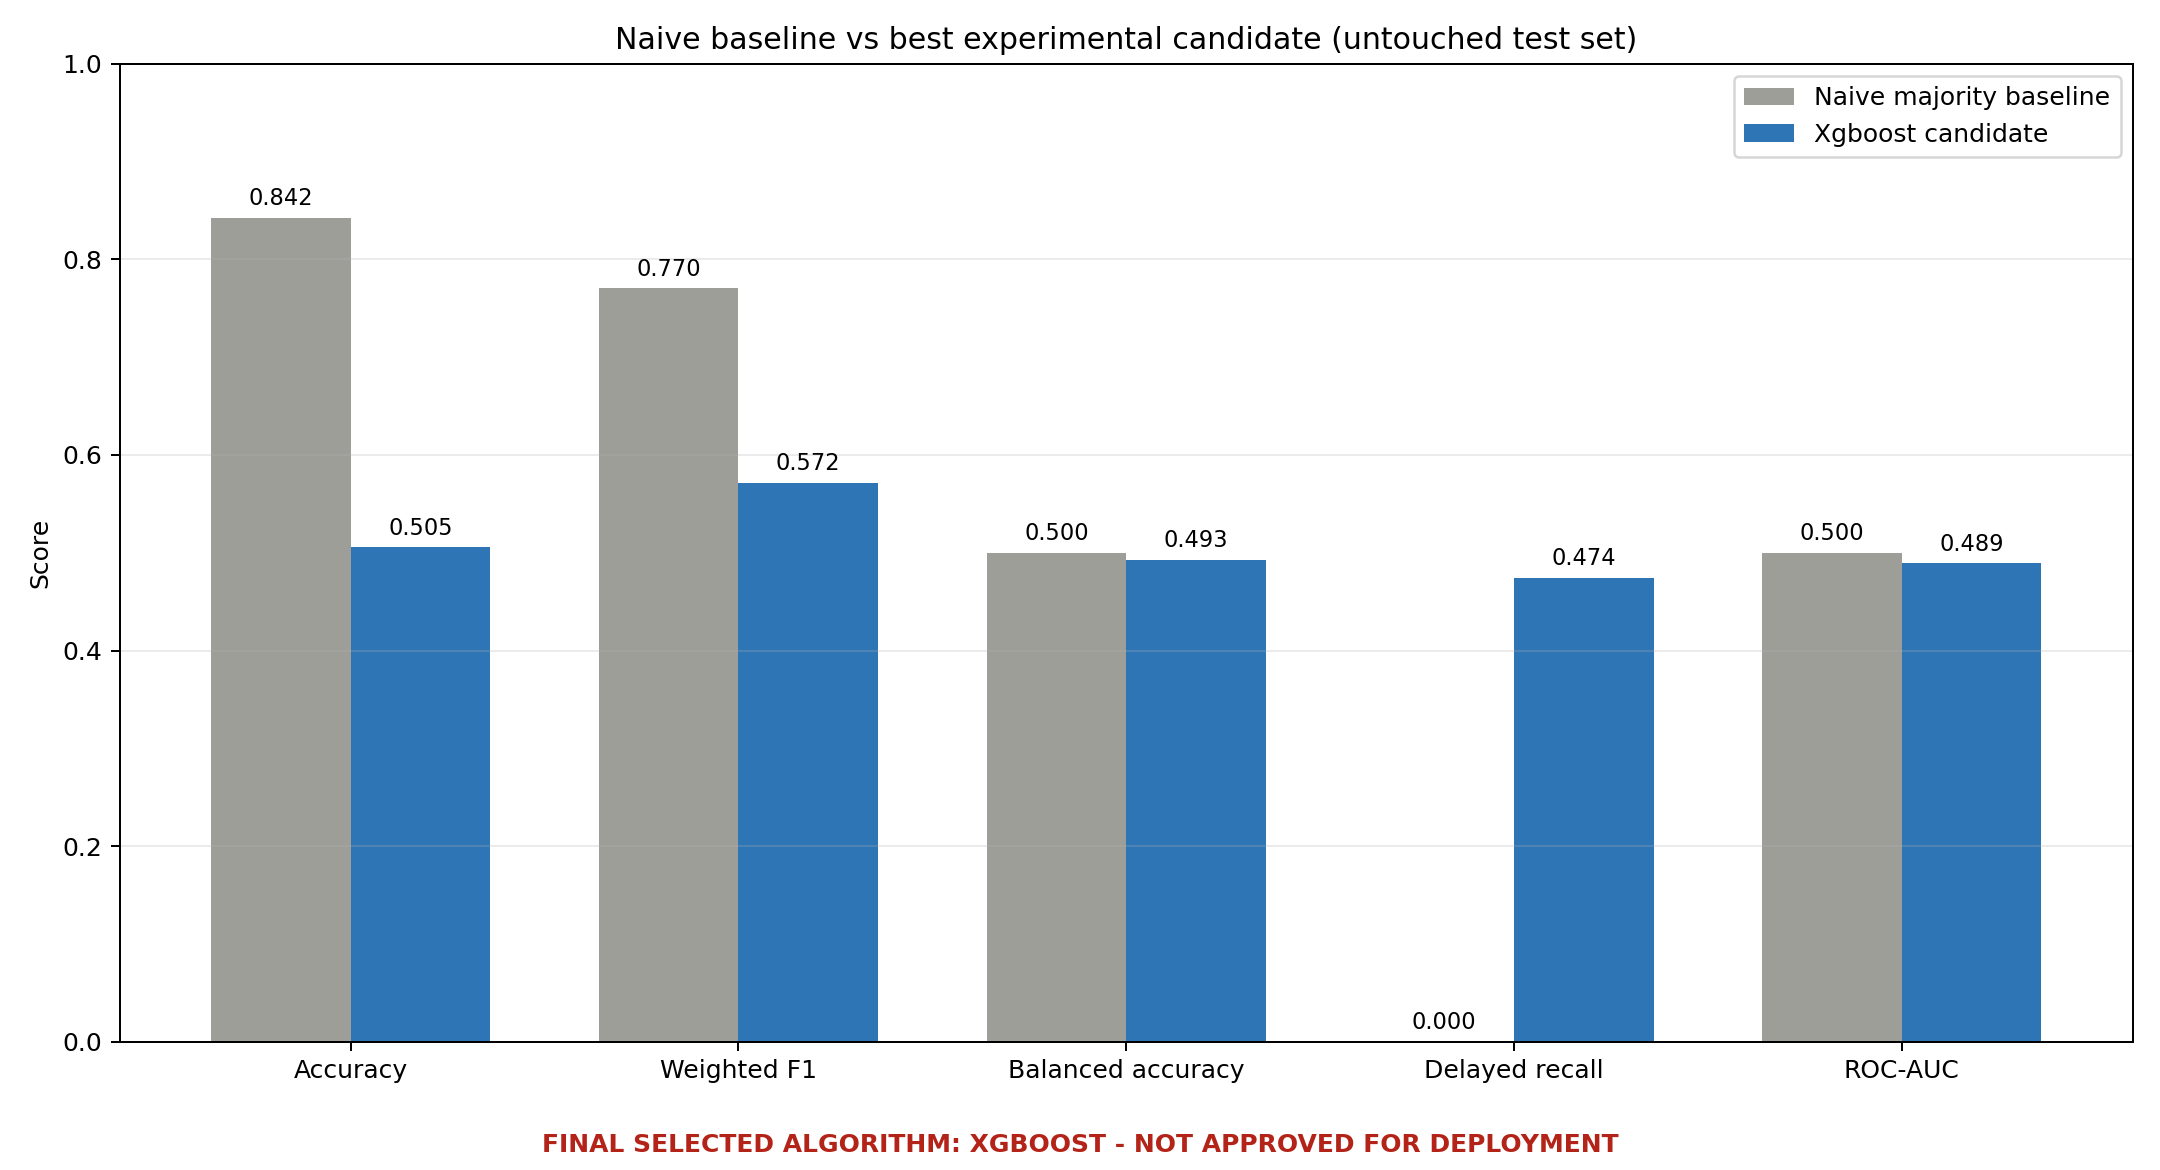

In [7]:
display(Image(filename=str(REPORTS / "naive_vs_best_candidate.png"), width=900))

### Conclusion

* With Returned removed, the task is a clean binary Delivered-vs-Delayed problem.
* The candidate's test ROC-AUC is about 0.49 (chance level): order-time attributes do not separate Delayed from Delivered orders.
* It catches some delayed orders only by flagging many delivered orders, so weighted F1 falls well below the baseline and the absolute net benefit is negative.
* The checkpoint is **RETURN_TO_BUSINESS_UNDERSTANDING**: the model is not deployed. The next iteration needs pre-outcome operational data (carrier, warehouse, route, promised SLA, dispatch backlog, weather).